In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [ ]:
def mostrar(imagens, titulos, cmap='gray', tamanho=4):
  n = len(imagens)
  plt.figure(figsize = (tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(imagens[i], cmap = cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

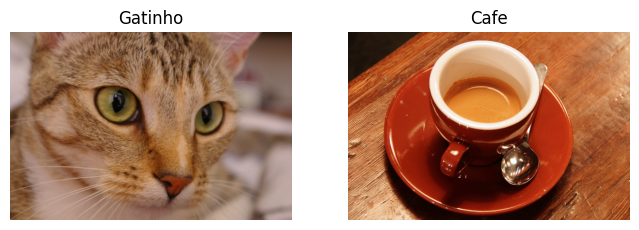

In [ ]:
mostrar([data.cat(), data.coffee()],('Gatinho', 'Cafe') )

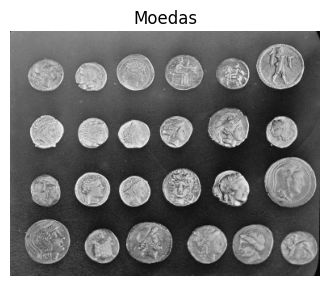

In [ ]:
moedas = data.coins()
mostrar([moedas], ['Moedas'])

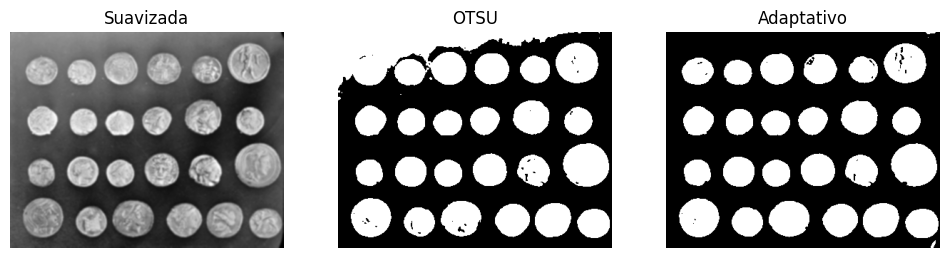

In [ ]:
suave = cv2.GaussianBlur(moedas, (5,5), 0)

_, mascara_otsu = cv2.threshold(suave, 0, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY) # Iluminação não uniforme fez ficar um pouco ruim
mascara_adapt   = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY,101, -20)

mostrar([suave, mascara_otsu, mascara_adapt],['Suavizada', 'OTSU', 'Adaptativo'])


array([[[ 47,  47,  47],
        [123, 123, 123],
        [133, 133, 133],
        ...,
        [ 14,  14,  14],
        [  3,   3,   3],
        [ 12,  12,  12]],

       [[ 93,  93,  93],
        [144, 144, 144],
        [145, 145, 145],
        ...,
        [ 12,  12,  12],
        [  7,   7,   7],
        [  7,   7,   7]],

       [[126, 126, 126],
        [147, 147, 147],
        [143, 143, 143],
        ...,
        [  2,   2,   2],
        [ 13,  13,  13],
        [  3,   3,   3]],

       ...,

       [[ 81,  81,  81],
        [ 79,  79,  79],
        [ 74,  74,  74],
        ...,
        [  6,   6,   6],
        [  4,   4,   4],
        [  7,   7,   7]],

       [[ 88,  88,  88],
        [ 82,  82,  82],
        [ 74,  74,  74],
        ...,
        [  5,   5,   5],
        [  7,   7,   7],
        [  8,   8,   8]],

       [[ 91,  91,  91],
        [ 79,  79,  79],
        [ 68,  68,  68],
        ...,
        [  4,   4,   4],
        [ 10,  10,  10],
        [  7,   7,   7]]], shape=(303, 384, 3), dtype=uint8)
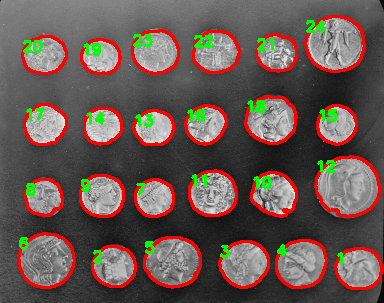

In [ ]:
contornos, _ = cv2.findContours(mascara_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Filtros contornos pequenos
contornos = [c for c in contornos if cv2.contourArea(c) > 500]

# Cria mascara final a partir dos contornos
mascara_final = np.zeros_like(mascara_adapt)

# Desenha os contornos na mascara final
cv2.drawContours(mascara_final, contornos, -1, 255, thickness = -1)

# Converte imagem original cinza em RGB
moedas_rgb = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)

# Sobrepoe os contornos na imagem original
cv2.drawContours(moedas_rgb, contornos, -1, (255,0,0), 2)

for i, c in enumerate(contornos): # Enumerate retorna uma tupla com os indices
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(moedas_rgb, str(i + 1), (x, y+15), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 2)
moedas_rgb

In [ ]:
import numpy as np, cv2, matplotlib.pyplot as plt
from skimage import data

def segmentar(img, bloco=101, C=-20, area_min=500, inverter=False):
    suave = cv2.GaussianBlur(img, (5,5), 0)
    tipo = cv2.THRESH_BINARY_INV if inverter else cv2.THRESH_BINARY
    mascara = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_MEAN_C, tipo, bloco, C)
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contornos = [c for c in contornos if cv2.contourArea(c) > area_min]

    # Semântica: todos os objetos = mesma classe (0 fundo, 255 objeto)
    semantica = np.zeros_like(mascara)
    cv2.drawContours(semantica, contornos, -1, 255, thickness=-1)

    # Instância: cada contorno recebe um id próprio (1..N)
    instancia = np.zeros(img.shape, dtype=np.int32)
    for i, c in enumerate(contornos, start=1):
        cv2.drawContours(instancia, [c], -1, i, thickness=-1)
    return semantica, instancia, len(contornos)

def plot_comparacao(img, semantica, instancia, n, classe):
    cores = plt.cm.nipy_spectral(np.linspace(0.05, 0.95, max(n,1)))
    np.random.seed(1); np.random.shuffle(cores)
    rgb = np.zeros((*instancia.shape, 3))
    for i in range(1, n+1):
        rgb[instancia == i] = cores[i-1][:3]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].imshow(img, cmap='gray'); ax[0].set_title('Entrada')
    ax[1].imshow(semantica, cmap='gray'); ax[1].set_title(f'Semântica (1 classe: {classe})')
    ax[2].imshow(rgb); ax[2].set_title(f'Instância (1 cor por {classe})')
    for a in ax: a.axis('off')
    plt.show()

In [ ]:
moedas = data.coins()
sem, inst, n = segmentar(moedas, bloco=101, C=-20, area_min=500)
print('Moedas encontradas:', n)
plot_comparacao(moedas, sem, inst, n, 'moeda')

In [ ]:
# Outra imagem do skimage: texto impresso (fundo claro -> inverter=True)
page = data.page()
sem2, inst2, n2 = segmentar(page, bloco=31, C=10, area_min=8, inverter=True)
print('Objetos encontrados:', n2)
plot_comparacao(page, sem2, inst2, n2, 'trecho de texto')